# 01 — Validating the engine against Erlang C

The depot model runs on a SimPy charger/queue engine. Before trusting it on the
realistic depot, we run the same engine in **validation mode** — a textbook
M/M/c queue (Poisson arrivals, exponential service, `c` identical servers,
FCFS, unlimited queue) — where the exact answer is known from Erlang C.

The realistic depot (shift schedules, a finite fleet, a power cap) breaks the
M/M/c assumptions, so Erlang C is **not** expected to match it. Validation is
done where the theory applies.

Method: 30 independent replications per point (seeds 0–29), 200,000 time units
each with the first 20,000 discarded as warm-up, one mean per run, and a 95%
confidence interval from Student's t with 29 degrees of freedom.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from depot_sim.config import ValidationConfig, DepotConfig
from depot_sim.runner import run_replications, summarise
from depot_sim.theory import mmc

N_JOBS = min(4, os.cpu_count() or 1)
BLUE, ORANGE = "#2a78d6", "#eb6834"   # categorical slots 1 and 2
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3dd"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})

## 1. The four-point validation grid

In [2]:
rows = []
for c in (3, 5):
    for rho in (0.6, 0.8):
        cfg = ValidationConfig.from_rho(rho, c)
        runs = run_replications(cfg, n_runs=30, n_jobs=N_JOBS)
        th = mmc(cfg.lam, cfg.mu, c)
        w, pw, u = (summarise(runs, k) for k in ("mean_wait", "p_wait", "utilisation"))
        rows.append({
            "c": c, "rho": rho,
            "Wq Erlang C": th.Wq, "Wq simulated": w.mean, "CI half-width": w.half_width,
            "CI low": w.low, "CI high": w.high,
            "rel. error %": 100 * (w.mean - th.Wq) / th.Wq,
            "half-width %": 100 * w.rel_half_width,
            "theory in CI": w.contains(th.Wq),
            "P(wait) Erlang C": th.p_wait, "P(wait) simulated": pw.mean,
            "utilisation simulated": u.mean,
        })
grid = pd.DataFrame(rows)
os.makedirs("../results", exist_ok=True)
grid.to_csv("../results/validation_grid.csv", index=False)
grid.round(4)

,c,rho,Wq Erlang C,Wq simulated,CI half-width,CI low,CI high,rel. error %,half-width %,theory in CI,P(wait) Erlang C,P(wait) simulated,utilisation simulated
0,3,0.6,0.2956,0.2967,0.0019,0.2948,0.2986,0.3594,0.6450,True,0.3547,0.3549,0.5999
1,3,0.8,1.0787,1.0806,0.0079,1.0727,1.0885,0.1776,0.7311,True,0.6472,0.6477,0.8004
2,5,0.6,0.1181,0.1178,0.0007,0.1170,0.1185,-0.2701,0.6087,True,0.2362,0.2360,0.5999
3,5,0.8,0.5541,0.5524,0.0035,0.5489,0.5558,-0.3148,0.6262,True,0.5541,0.5535,0.7998


Every point: simulated mean within 5% of Erlang C, and the Erlang C value
inside the 95% confidence interval. Utilisation and P(wait) match theory too —
three independent quantities, not one.

## 2. Warm-up check

The queue starts empty, which biases early waits downward. If 20,000 time
units of warm-up is enough, doubling it should not move the estimate beyond
noise.

In [3]:
cmp = []
for warm in (20_000.0, 40_000.0):
    cfg = ValidationConfig.from_rho(0.8, 5, warmup=warm, horizon=180_000.0 + warm)
    ci = summarise(run_replications(cfg, n_runs=30, n_jobs=N_JOBS), "mean_wait")
    cmp.append({"warm-up": warm, "measured span": 180_000.0, "Wq simulated": ci.mean,
                "CI low": ci.low, "CI high": ci.high})
th = mmc(4.0, 1.0, 5).Wq
warm = pd.DataFrame(cmp)
warm["Wq Erlang C"] = th
warm.round(4)

,warm-up,measured span,Wq simulated,CI low,CI high,Wq Erlang C
0,20000.0,180000.0,0.5524,0.5489,0.5558,0.5541
1,40000.0,180000.0,0.5528,0.5499,0.5558,0.5541


Both estimates overlap each other and contain the analytical value: the
warm-up is long enough. (Both runs measure the same 180,000-unit span, so only
the warm-up changes.)

## 3. Across the load range

Shorter runs (50,000 units, 10 replications) across ρ = 0.5–0.9. Lines are
Erlang C; points are simulated means with 95% CIs.

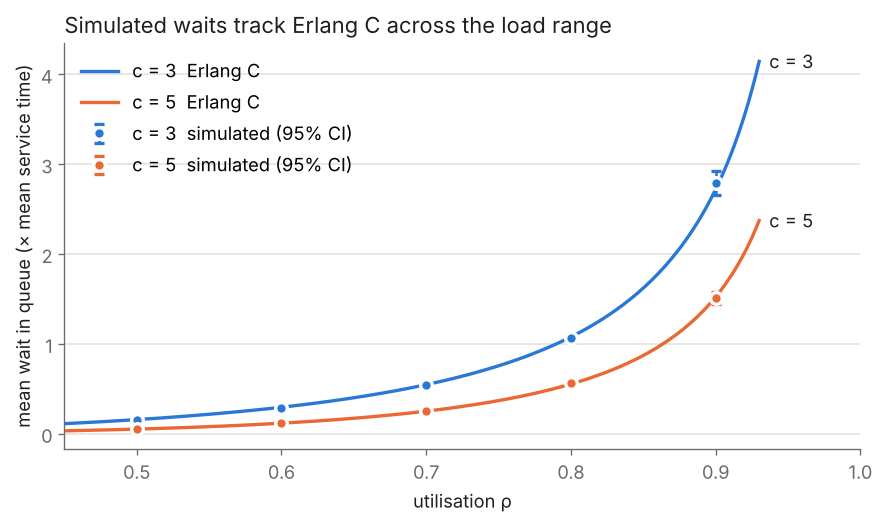

In [4]:
rhos = np.round(np.arange(0.5, 0.91, 0.1), 2)
curve = []
for c in (3, 5):
    for rho in rhos:
        cfg = ValidationConfig.from_rho(rho, c, horizon=50_000.0, warmup=5_000.0)
        ci = summarise(run_replications(cfg, n_runs=10, n_jobs=N_JOBS), "mean_wait")
        curve.append({"c": c, "rho": rho, "sim": ci.mean, "hw": ci.half_width})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(7.5, 4.5), dpi=120)
fine = np.linspace(0.45, 0.93, 200)
for c, col in ((3, BLUE), (5, ORANGE)):
    ax.plot(fine, [mmc(r * c, 1.0, c).Wq for r in fine], color=col, lw=2, label=f"c = {c}  Erlang C")
    d = curve[curve.c == c]
    ax.errorbar(d.rho, d.sim, yerr=d.hw, fmt="o", ms=7, color=col, mec="white", mew=2,
                capsize=3, label=f"c = {c}  simulated (95% CI)")
    ax.annotate(f"c = {c}", (0.93, mmc(0.93 * c, 1.0, c).Wq), xytext=(6, 0),
                textcoords="offset points", color=INK, va="center")
ax.set_xlabel("utilisation ρ")
ax.set_ylabel("mean wait in queue (× mean service time)")
ax.set_title("Simulated waits track Erlang C across the load range", loc="left", color=INK)
ax.grid(axis="y", color=GRID, lw=1)
ax.legend(frameon=False, loc="upper left")
ax.set_xlim(0.45, 1.0)
plt.tight_layout()
plt.savefig("../results/validation_curve.png", dpi=160)
plt.show()

## 4. Depot mode, end to end

The realistic depot with its defaults (50 vans, 5 × 50 kW chargers, 400 kW
cap, FCFS), 30 replications of 15 days with day 0 discarded. No theory to
compare against here — these are the model's outputs, with their uncertainty.

In [5]:
runs = run_replications(DepotConfig(), n_runs=30, n_jobs=N_JOBS)
keys = {"mean_wait": "mean wait (h)", "p95_wait": "95th pct wait (h)",
        "utilisation": "charger utilisation (24 h)", "on_time": "on-time departures",
        "peak_power_kw": "peak site power (kW)", "energy_per_day_kwh": "energy per day (kWh)"}
depot = pd.DataFrame([{"metric": label, "mean": summarise(runs, k).mean,
                       "95% CI ±": summarise(runs, k).half_width} for k, label in keys.items()])
depot.round(3)

,metric,mean,95% CI ±
0,mean wait (h),1.469,0.025
1,95th pct wait (h),3.113,0.047
2,charger utilisation (24 h),0.292,0.001
3,on-time departures,1.000,0.000
4,peak site power (kW),250.000,0.000
5,energy per day (kWh),1749.590,7.147
